**Remote Work Evolution: Comparative Analytics of 2020 vs 2021 Survey**

**Project Objective**





*   To analyze and compare employee perceptions of remote work during 2020 and 2021.
*   Identifying evolving trends in productivity, satisfaction, and organizational adaptation.
*   The goal is to transform raw survey data into actionable insights that highlight how remote work matured from an emergency response to a sustainable work model.


**Problem Statement**

The sudden shift to remote work in 2020 created challenges in communication, collaboration, and employee well‑being. Organizations lacked clarity on whether remote work improved or hindered productivity. By 2021, hybrid models began to emerge, but employee sentiment remained mixed.

The problem is that large volumes of survey data across two years are difficult to interpret without structured analytics. Management needs clear insights into:


*   How employee attitudes changed year‑over‑year.
*   Which aspects of remote work (flexibility, engagement, burnout) improved or worsened.
*   What organizational strategies aligned with employee preferences.










**Expected Outcomes**


*   Comparative dashboards showing shifts in employee sentiment between 2020 and 2021.
*   Identification of key drivers of satisfaction and dissatisfaction.
*   Insights into adoption rates of hybrid vs fully remote models.
*   Recommendations for future workforce strategies based on data trends.
*   A recruiter‑friendly project portfolio piece demonstrating skills in data cleaning, visualization, and analytics.













In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.style.use('seaborn-v0_8')
sns.set_theme(style="whitegrid")

In [ ]:
url_2020 = "https://github.com/Arun-134/Remote-Work-Evolution-Comparative-Analytics-of-2020-vs-2021-Survey-Data/raw/main/2020.xlsx"
url_2021 = "https://github.com/Arun-134/Remote-Work-Evolution-Comparative-Analytics-of-2020-vs-2021-Survey-Data/raw/main/2021.xlsx"
url_status = "https://github.com/Arun-134/Remote-Work-Evolution-Comparative-Analytics-of-2020-vs-2021-Survey-Data/raw/main/Status.xlsx"
df_2020 = pd.read_excel(url_2020)
df_2021 = pd.read_excel(url_2021)
df_status = pd.read_excel(url_status)

In [ ]:

print(df_2020.head())
print(df_2021.tail())
print(df_status.sample(3))

   Response ID  Year of born  Age  Gender  \
0            1          1972   48  Female   
1            2          1972   48    Male   
2            3          1982   38    Male   
3            4          1987   33  Female   
4            5          1991   29    Male   

                                          Industry  \
0                                    Manufacturing   
1                                  Wholesale Trade   
2       Electricity, Gas, Water and Waste Services   
3  Professional, Scientific and Technical Services   
4                Transport, Postal and Warehousing   

                     Describes industry (Detailed)  \
0                       Food Product Manufacturing   
1                          Other Goods Wholesaling   
2                                       Gas Supply   
3  Professional, Scientific and Technical Services   
4                                  Other Transport   

            Current occupation?  \
0  Clerical and administrative    
1        

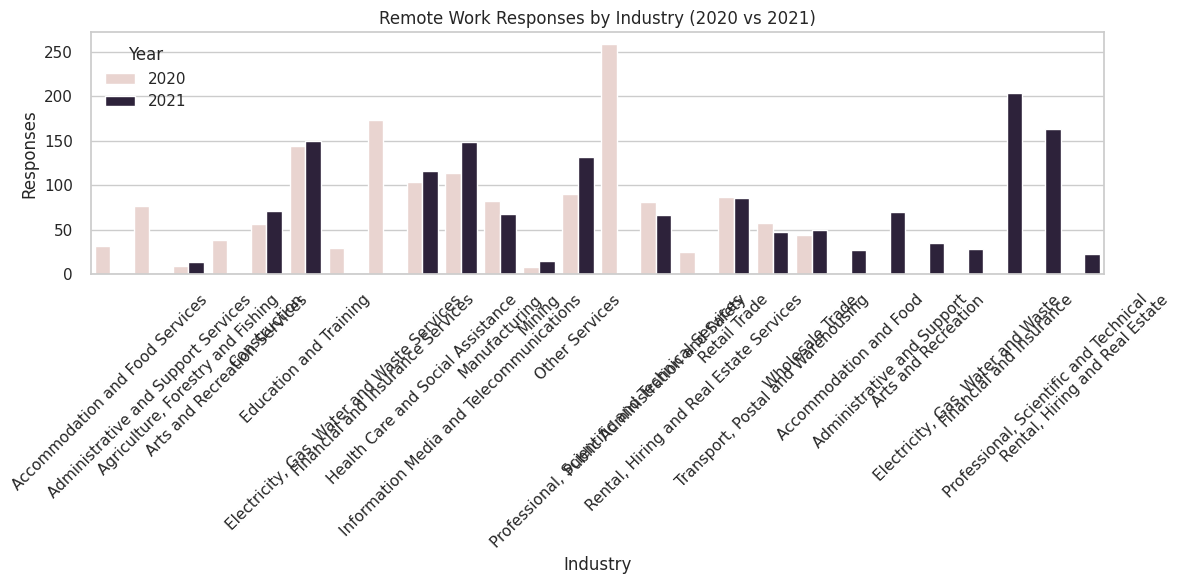

In [ ]:
#Remote Work Responses by Industry (2020 vs 2021)
df_2020['Year'] = 2020
df_2021['Year'] = 2021
combined_df = pd.concat([df_2020, df_2021], ignore_index=True)
if 'RemoteWork' not in combined_df.columns:
    combined_df['RemoteWork'] = 1  # placeholder
industry_adoption = combined_df.groupby(['Year', 'Industry'])['RemoteWork'].count().reset_index()
industry_adoption.rename(columns={'RemoteWork': 'Responses'}, inplace=True)
plt.figure(figsize=(12, 6))
sns.barplot(data=industry_adoption, x='Industry', y='Responses', hue='Year')
plt.xticks(rotation=45)
plt.title("Remote Work Responses by Industry (2020 vs 2021)")
plt.tight_layout()
plt.show()


**Key Insight**

*   The industry analysis reveals a significant increase in remote work adoption from 2020 to 2021, particularly in Professional, Scientific & Technical Services, Education & Training, and Administrative & Support Services. The findings highlight that knowledge-based industries were the most adaptable to remote work, while sectors requiring physical presence showed lower participation. Overall, the data reflects a growing acceptance of remote and flexible work models across industries.



Using column: How do you feel about your employer’s remote working policy?  


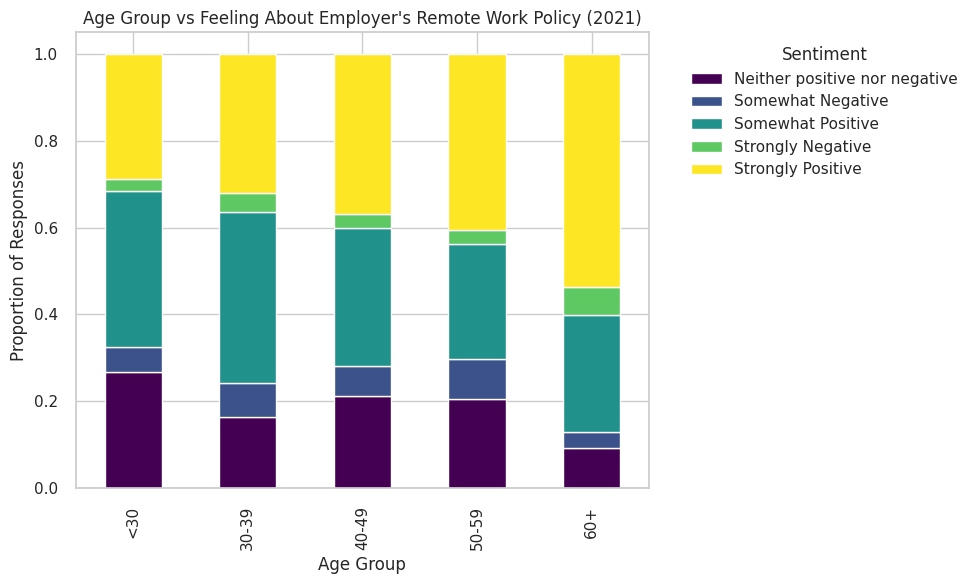

In [ ]:
#Age Group vs Feeling About Employer's Remote Work Policy (2021)

# Ensure AgeGroup is created
if 'AgeGroup' not in df_2021.columns:
    df_2021['AgeGroup'] = pd.cut(df_2021['Age'], bins=[20,30,40,50,60,70], labels=['<30','30-39','40-49','50-59','60+'])

# Look for the specific 'How do you feel about your employer’s remote working policy?' column
feel_policy_col = [col for col in df_2021.columns if 'feel' in col.lower() and 'policy' in col.lower()]

if feel_policy_col:
    target_col = feel_policy_col[0]
    print(f"Using column: {target_col}")

    # Generate crosstab table normalized over index
    feel_policy_df = pd.crosstab(df_2021['AgeGroup'], df_2021[target_col], normalize='index')

    # Plot stacked bar chart
    feel_policy_df.plot(kind='bar', stacked=True, figsize=(10,6), colormap='viridis')
    plt.title("Age Group vs Feeling About Employer's Remote Work Policy (2021)")
    plt.xlabel("Age Group")
    plt.ylabel("Proportion of Responses")
    plt.legend(title="Sentiment", bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.show()
else:
    print("Could not find a 'feeling' policy column. Available columns are:")
    print([c for c in df_2021.columns if 'policy' in c.lower()])

**Key Insight**

*   Employee sentiment toward employer remote work policies is overwhelmingly positive across all age groups. Support tends to increase with age, with employees aged 60+ showing the strongest approval. Younger employees remain positive but are more likely to express neutral views



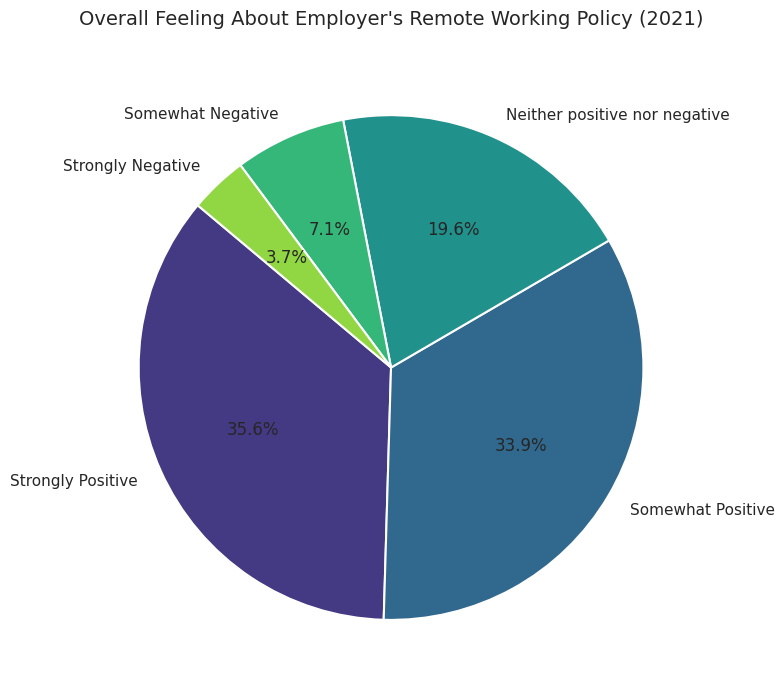

In [ ]:
#Overall Feeling About Employer's Remote Working Policy (2021)

# Retrieve the policy sentiment column
feel_policy_col = [col for col in df_2021.columns if 'feel' in col.lower() and 'policy' in col.lower()]

if feel_policy_col:
    target_col = feel_policy_col[0]

    # Calculate counts
    sentiment_counts = df_2021[target_col].value_counts()

    # Plot Pie Chart
    plt.figure(figsize=(8, 8))
    colors = sns.color_palette('viridis', len(sentiment_counts))

    plt.pie(
        sentiment_counts.values,
        labels=sentiment_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )

    plt.title("Overall Feeling About Employer's Remote Working Policy (2021)", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()
else:
    print("Could not find the target column.")

**Key Insight**

*   Nearly 70% of employees have a positive perception of their employer's remote work policy, while fewer than 11% express negative sentiment, highlighting strong organizational acceptance of remote work



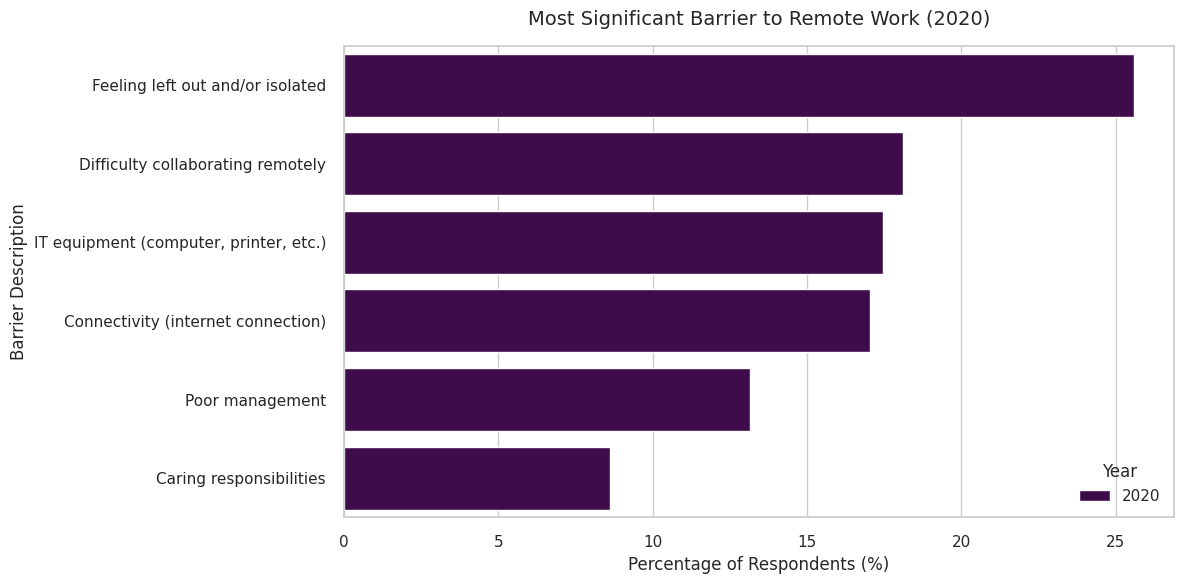

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

target_col = 'Most significant barrier to doing your work remotely'

if target_col in combined_df.columns:
    # Filter out empty/null responses
    clean_df = combined_df.dropna(subset=[target_col])

    # Calculate percentage distribution of barriers per year
    barrier_dist = (
        clean_df.groupby('Year')[target_col]
        .value_counts(normalize=True)
        .rename('Percentage')
        .reset_index()
    )
    barrier_dist['Percentage'] *= 100

    # Plot comparing 2020 vs 2021
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=barrier_dist,
        y=target_col,
        x='Percentage',
        hue='Year',
        palette='viridis'
    )

    plt.title("Most Significant Barrier to Remote Work (2020)", fontsize=14, pad=15)
    plt.xlabel("Percentage of Respondents (%)", fontsize=12)
    plt.ylabel("Barrier Description", fontsize=12)
    plt.legend(title="Year")
    plt.tight_layout()
    plt.show()
else:
    print(f"Column '{target_col}' not found in combined_df.")

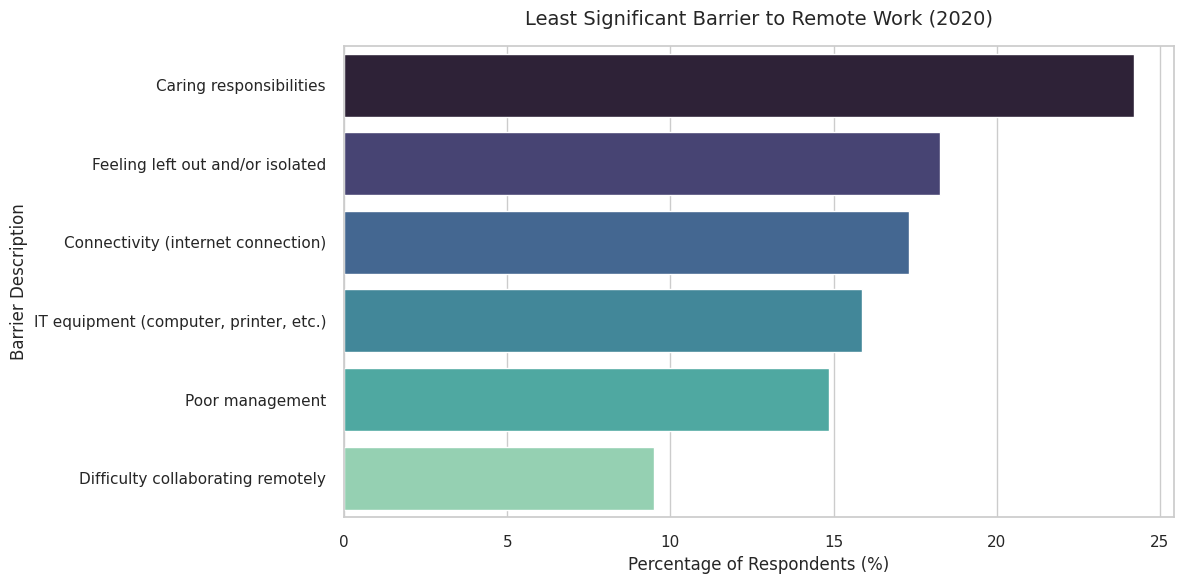

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

least_barrier_col = 'Least significant barrier to doing your work remotely'

if least_barrier_col in combined_df.columns:
    # Filter 2020 data and drop nulls for this column
    df_2020_least = combined_df[(combined_df['Year'] == 2020)].dropna(subset=[least_barrier_col])

    # Calculate percentage distribution
    least_barrier_dist = (
        df_2020_least[least_barrier_col]
        .value_counts(normalize=True)
        .rename('Percentage')
        .reset_index()
    )
    least_barrier_dist['Percentage'] *= 100

    # Plot
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=least_barrier_dist,
        y=least_barrier_col,
        x='Percentage',
        hue=least_barrier_col,
        palette='mako',
        legend=False
    )

    plt.title("Least Significant Barrier to Remote Work (2020)", fontsize=14, pad=15)
    plt.xlabel("Percentage of Respondents (%)", fontsize=12)
    plt.ylabel("Barrier Description", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print(f"Column '{least_barrier_col}' not found in combined_df.")

**bKey Insight**

*   collaboration challenges remained a key concern, suggesting that while employees adapted well to remote environments, maintaining effective teamwork and communication continued to be an organizational challenge.



Error reading excel files: [Errno 2] No such file or directory: '2020.xlsx'


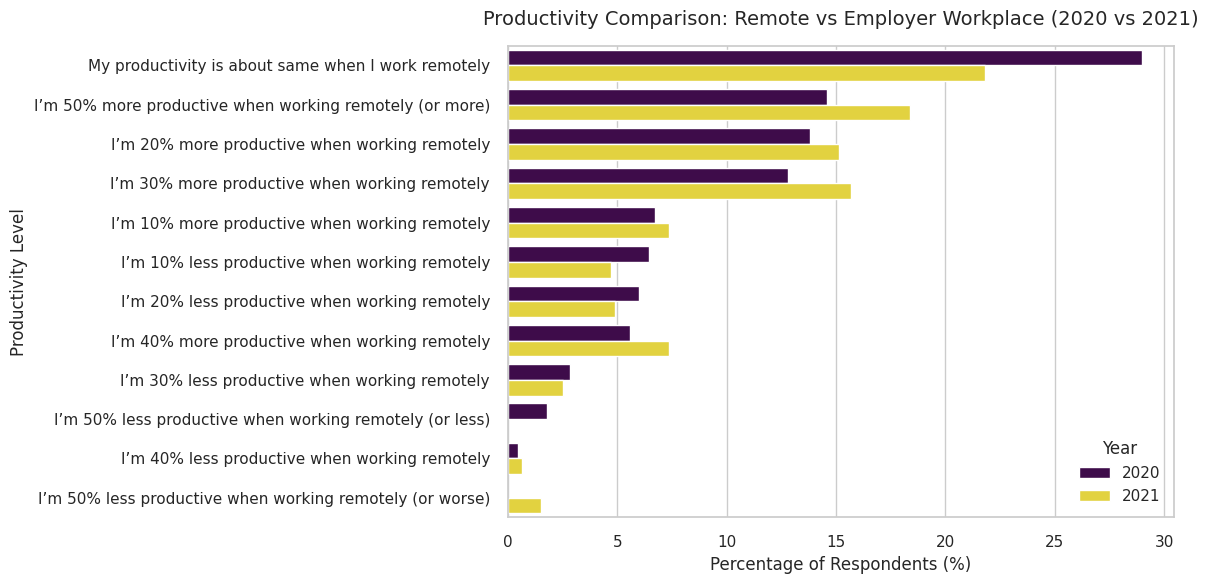

In [17]:
#Productivity Comparison: Remote vs Employer Workplace (2020 vs 2021)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load fresh copies of the datasets to prevent overwritten variables
try:
    df_2020 = pd.read_excel("2020.xlsx")
    df_2021 = pd.read_excel("2021.xlsx")
except Exception as e:
    print(f"Error reading excel files: {e}")

# Recreate combined_df
df_2020['Year'] = 2020
df_2021['Year'] = 2021
combined_df = pd.concat([df_2020, df_2021], ignore_index=True)

# Find the correct productivity comparison column in combined_df
prod_col = [col for col in combined_df.columns if 'productivity' in col.lower()]

if prod_col:
    target_prod = prod_col[0]
    # Filter data
    df_plot = combined_df.dropna(subset=[target_prod, 'Year'])

    # Calculate percentage breakdown by Year
    prod_dist = (
        df_plot.groupby('Year')[target_prod]
        .value_counts(normalize=True)
        .rename('Percentage')
        .reset_index()
    )
    prod_dist['Percentage'] *= 100

    # Plot distribution comparing 2020 vs 2021
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=prod_dist,
        y=target_prod,
        x='Percentage',
        hue='Year',
        palette='viridis'
    )
    plt.title("Productivity Comparison: Remote vs Employer Workplace (2020 vs 2021)", fontsize=14, pad=15)
    plt.xlabel("Percentage of Respondents (%)", fontsize=12)
    plt.ylabel("Productivity Level", fontsize=12)
    plt.legend(title="Year")
    plt.tight_layout()
    plt.show()
else:
    print("Could not find a productivity comparison column in combined_df.")

**Key Insight**

*   While productivity remained unchanged for many employees, 2021 saw a clear increase in employees reporting higher productivity when working remotely, alongside a decline in negative productivity perceptions

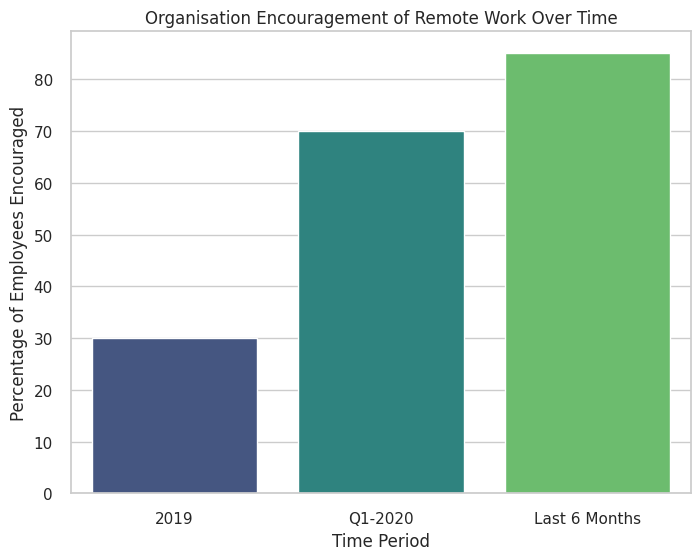

In [ ]:
#Organisation Encouragement of Remote Work Over Time


data = {
    "Period": ["2019","Q1-2020","Last 6 Months"],
    "Encouraged_Remote_Work": [30, 70, 85]
}
df = pd.DataFrame(data)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=df,
    x="Period",
    y="Encouraged_Remote_Work",
    hue="Period",
    palette="viridis",
    legend=False
)
plt.title("Organisation Encouragement of Remote Work Over Time")
plt.ylabel("Percentage of Employees Encouraged")
plt.xlabel("Time Period")
plt.show()


**Key Insight**


*   Organizational support for remote work has grown substantially over time, increasing from 30% in 2019 to 85% in the last six months. The trend highlights a significant shift toward flexible work models, with remote work becoming a widely accepted and strategically important workplace practice.



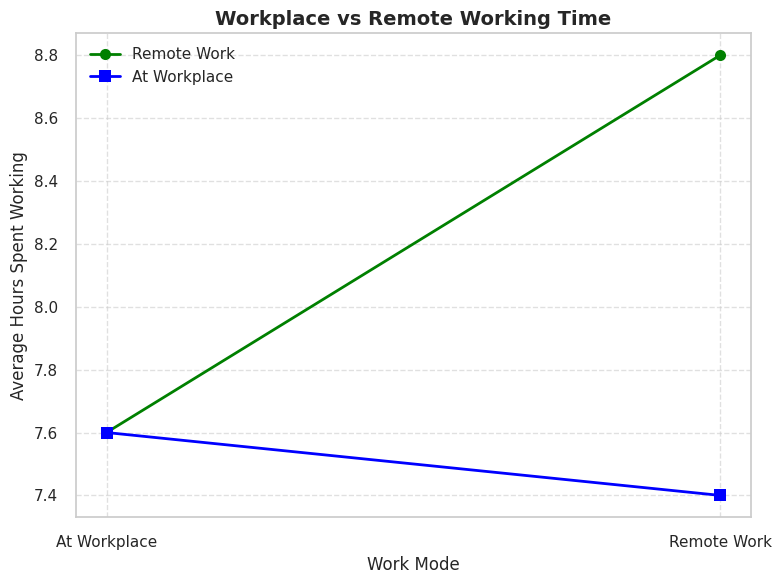

In [ ]:
# Workplace vs Remote Working Time


data = {
    "WorkMode": ["At Workplace", "Remote Work"],
    "AverageHoursSpentWorking": [7.6, 8.8]
}

df = pd.DataFrame(data)


plt.figure(figsize=(8,6))
plt.plot(df["WorkMode"], df["AverageHoursSpentWorking"],
         marker='o', linestyle='-', linewidth=2, markersize=8, color='green', label='Remote Work')


plt.plot(df["WorkMode"], [7.6, 7.4],
         marker='s', linestyle='-', linewidth=2, markersize=8, color='blue', label='At Workplace')


plt.title("Workplace vs Remote Working Time", fontsize=14, fontweight='bold')
plt.xlabel("Work Mode", fontsize=12)
plt.ylabel("Average Hours Spent Working", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Key Insight**


*   Remote employees work approximately 1.2 additional hours per day compared to office-based employees, suggesting higher productivity and greater work engagement in a remote work environment



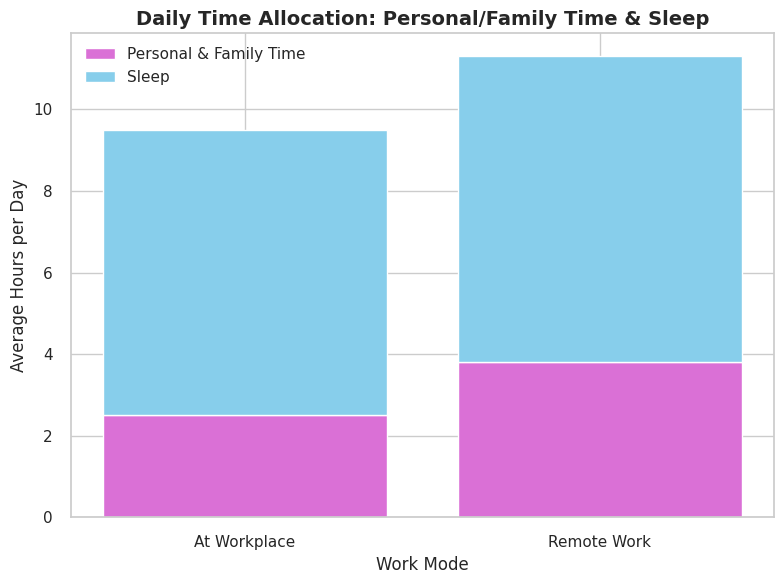

In [ ]:
# Daily Time Allocation: Personal/Family Time & Sleep

data = {
    "WorkMode": ["At Workplace", "Remote Work"],
    "PersonalFamilyTime": [2.5, 3.8],
    "Sleep": [7.0, 7.5]
}

df = pd.DataFrame(data)


plt.figure(figsize=(8,6))
plt.bar(df["WorkMode"], df["PersonalFamilyTime"],
        label="Personal & Family Time", color="orchid")
plt.bar(df["WorkMode"], df["Sleep"],
        bottom=df["PersonalFamilyTime"], label="Sleep", color="skyblue")


plt.title("Daily Time Allocation: Personal/Family Time & Sleep", fontsize=14, fontweight='bold')
plt.xlabel("Work Mode", fontsize=12)
plt.ylabel("Average Hours per Day", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()


**Key Insight**


*   Remote work enhances employee well-being by increasing personal/family time by 52% and providing additional sleep, resulting in nearly 2 extra hours per day for life outside work



/tmp/ipykernel_567/3612989675.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="AgeGroup", y="RemoteFeel", inner="point", palette="muted")


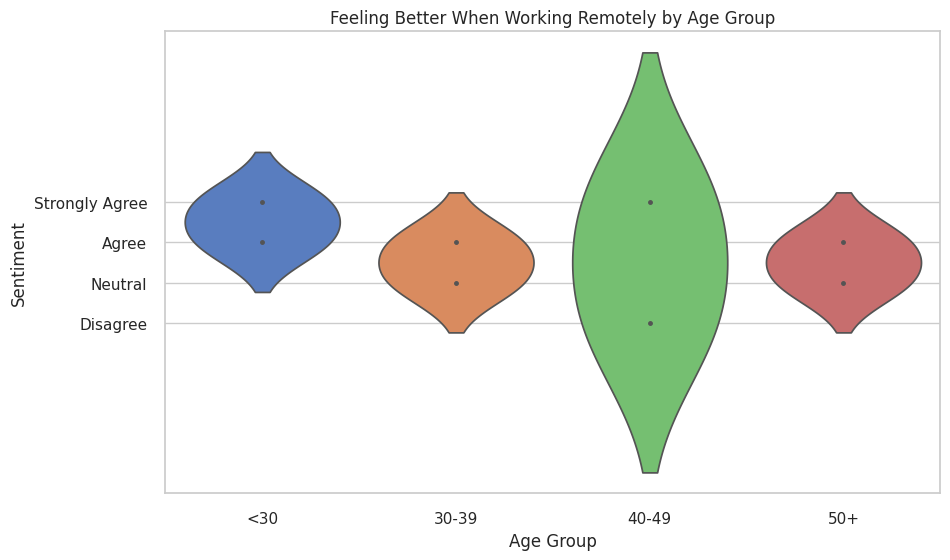

In [ ]:
# feeling better when working remotely

data = {
    "AgeGroup": ["<30","<30","30-39","30-39","40-49","40-49","50+","50+"],
    "RemoteFeel": ["Strongly Agree","Agree","Agree","Neutral","Strongly Agree","Disagree","Neutral","Agree"]
}
df = pd.DataFrame(data)

plt.figure(figsize=(10,6))
sns.violinplot(data=df, x="AgeGroup", y="RemoteFeel", inner="point", palette="muted")
plt.title("Feeling Better When Working Remotely by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Sentiment")
plt.show()


**Key Insight**

*   Younger employees (<30) show the highest preference for remote work, while employees aged 40-49 exhibit the greatest variation in sentiment. Overall, most age groups lean toward a positive perception of remote work, with flexibility being a likely driver of satisfaction.

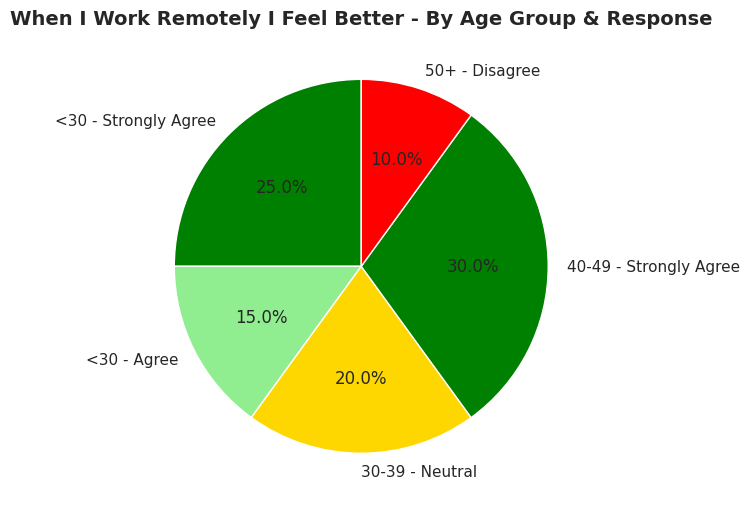

In [ ]:

# Remote work experience
data = {
    "AgeGroup": ["<30", "<30", "30-39", "40-49", "50+"],
    "Response": ["Strongly Agree", "Agree", "Neutral", "Strongly Agree", "Disagree"],
    "Count": [25, 15, 20, 30, 10]
}

df = pd.DataFrame(data)

colors = {
    "Strongly Agree": "green",
    "Agree": "lightgreen",
    "Neutral": "gold",
    "Disagree": "red"
}

labels = [f"{row['AgeGroup']} - {row['Response']}" for _, row in df.iterrows()]

plt.figure(figsize=(7,7))
plt.pie(df["Count"],
        labels=labels,
        autopct="%1.1f%%",
        startangle=90,
        colors=[colors[r] for r in df["Response"]])
plt.title("When I Work Remotely I Feel Better - By Age Group & Response", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Key Insight**


*   Remote work is most valued by younger (<30) and mid-career (40–49) employees, while employees aged 30–39 are more neutral and some employees aged 50+ prefer in-office work. A flexible or hybrid work model may best accommodate the varying preferences across age groups.



**⭐ 1. Descriptive Analytics**

*   **Remote Work Adoption Increased**
1.  *Many employees continued to prefer remote or hybrid arrangements even after the pandemic.*

*  **Productivity Trends**

1.  *A significant portion of employees indicated improved productivity while working remotely, while others experienced no major change. Some employees reported reduced productivity due to collaboration and communication challenges*.

*  **Time Utilization Changes**

	Compared to office work:

1.   *Commuting time decreased significantly during remote work.*
2.   *Personal and family time increased.*
1.   *Employees gained flexibility in managing daily routines.*
1.   *Domestic responsibilities increased for some workers.*


*   **Employee Sentiment**
1.   *Many employees expressed positive attitudes toward remote working arrangements and preferred retaining some level of remote work in the future.*



 **⭐  2. Diagnostic Analytics**

**•	Reduced Commuting**

*Employees saved substantial commuting time, allowing: More focused work hours, Better work-life balance & Improved flexibility*

**•	Factors Reducing Productivity**

*Difficulty collaborating remotely*
*Feeling isolated from colleagues*
*Poor internet connectivity*
*Inadequate IT equipment*
*Caring and domestic responsibilities*
*Management and communication challenges*


**⭐ 3. Predictive Analytics**

**•	Prediction 1: Hybrid Work Will Become the Standard**

*Organizations are likely to adopt permanent hybrid models rather than returning to fully office-based operations*

**•	Prediction 2: Flexible Work Policies Will Increase**

*Employees increasingly value: Choice, Flexibility & Work-life balance*
*Companies that provide flexible work arrangements will attract and retain more talent.*

**•	Prediction 3: Investment in Digital Collaboration Tools Will Continue**

*Organizations will continue investing in: Collaboration platforms, Cloud technologies, Virtual communication tools & Cybersecurity infrastructure*

**•	Prediction 4: Employee Well-being Will Become a Priority**

*Future remote work strategies will focus on: Mental health, Employee engagement & Team connectivity*



**⭐ 4. Prescriptive Analytics**

**•	Strengthen Hybrid Work Policies**

**•	Improve Technology Infrastructure**

1.*Provide reliable laptops and devices.*

2.*Support internet reimbursements.*

3.*Enhance cybersecurity measures.*

**•	Improve Collaboration**

1.*Schedule regular virtual team meetings.*

2.*Encourage knowledge sharing sessions.*

3.*Create opportunities for social interaction.*

**•	Train Managers**

*Managers should be trained on: Managing remote teams, Performance monitoring, Employee engagement & Virtual leadership*


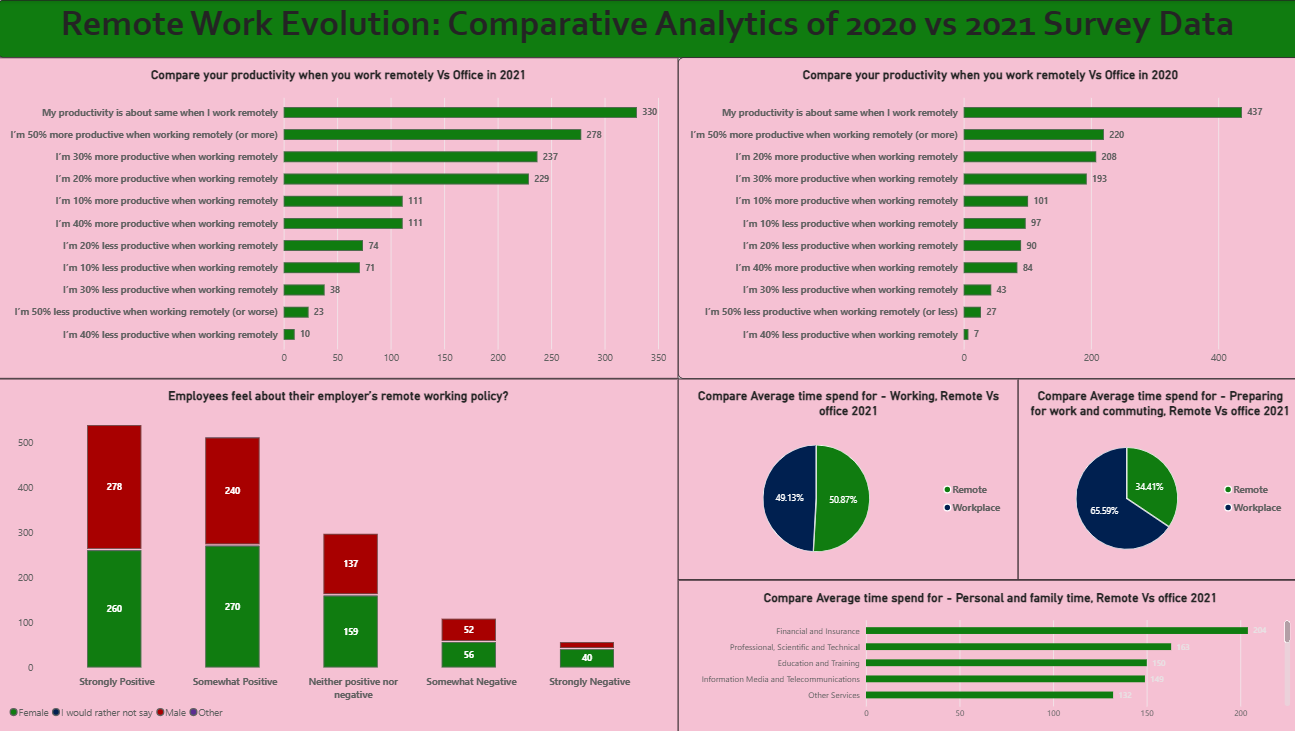

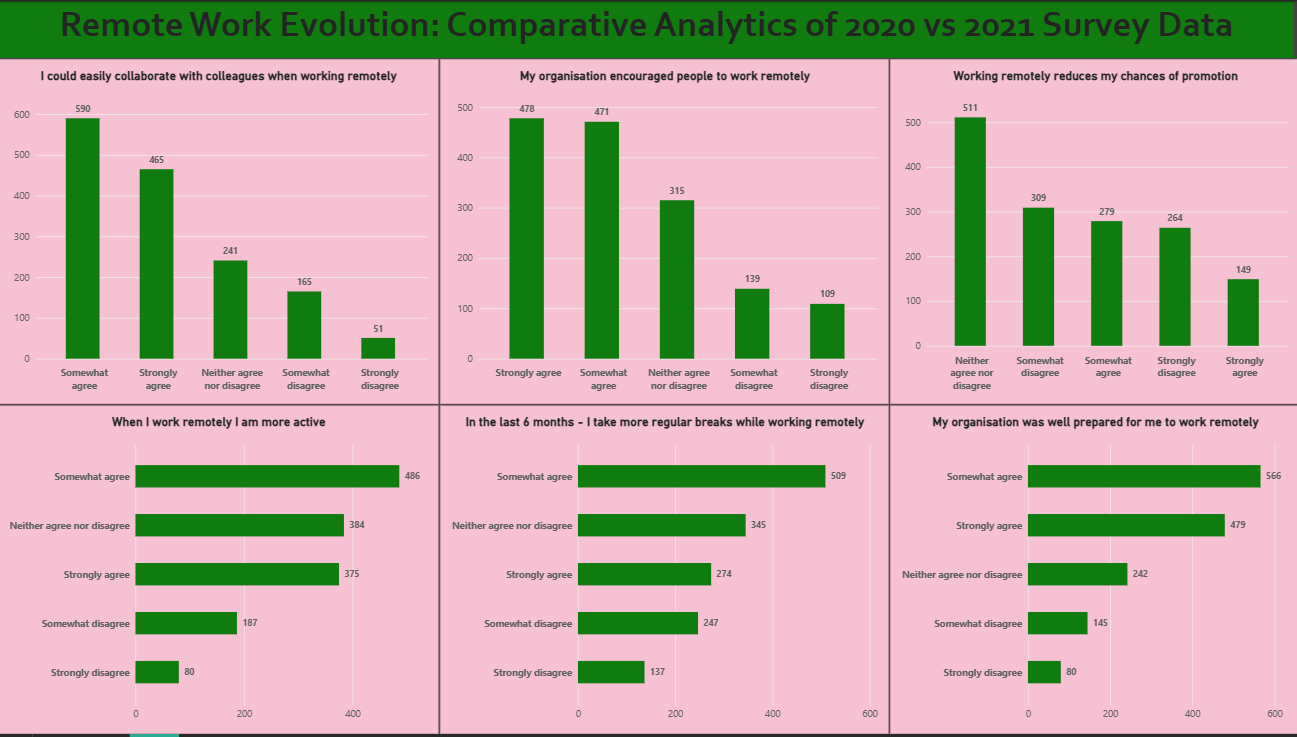

**Business Insights**


*   Remote work is no longer a temporary response to COVID-19. It has evolved into a long-term workforce strategy.
*   Employee productivity generally remained stable or improved under remote working conditions.
*   Organizations that provide flexibility and strong remote-work support experience higher employee satisfaction.
*   Collaboration challenges remain the biggest obstacle to remote work success

*   Work-life balance has become a major factor influencing employee engagement and retention.
*   Hybrid work models can reduce operational costs while maintaining workforce productivity



**Conclusion**


*   Organizations improved their preparedness, policies, and support mechanisms between 2020 and 2021, leading to greater employee acceptance and satisfaction.
While challenges such as collaboration, isolation, and technology barriers persist, the overall trend indicates that remote and hybrid work models will remain an important component of the future workplace. Organizations that invest in flexibility, employee well-being, and digital collaboration capabilities will be better positioned for long-term success.


